In [2]:
import numpy as np
import pandas as pd

In [57]:
movies = pd.DataFrame({
    "Movies_ID": [1, 2, 3, 4, 5, 6, 7, 8],
    "Movies_title":["Avengers", "Iron man", "Titanice", "Interseller",
                   "The Dark Knight", "Inception", "Avatar", "Joker"],
    "Genre": ["Action", "Action", "Romance", "Sci-Fi",
             "Action", "Sci-Fi", "Sci-Fi", "Drama"],
    "rating": [4.8, 4.5, 4.2, 4.7, 4.9, 4.6, 4.3, 4.1],
    "votes": [5000, 3500, 4200, 4800, 6000, 5500, 3900, 2800]
})

movies

,Movies_ID,Movies_title,Genre,rating,votes
0,1,Avengers,Action,4.8,5000
1,2,Iron man,Action,4.5,3500
2,3,Titanice,Romance,4.2,4200
3,4,Interseller,Sci-Fi,4.7,4800
4,5,The Dark Knight,Action,4.9,6000
5,6,Inception,Sci-Fi,4.6,5500
6,7,Avatar,Sci-Fi,4.3,3900
7,8,Joker,Drama,4.1,2800


In [7]:
# Explore the data
print("Dataset Shape:", movies.shape)
print("\nDataset Information:-")
movies.info()
print("\nMissing Values:")
print(movies.isnull().sum())
print("\nTop 5 Movies by rating:")
print(movies.sort_values(by="rating", ascending=False).head())

Dataset Shape: (8, 5)

Dataset Information:-
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Movies_ID     8 non-null      int64  
 1   Movies_title  8 non-null      str    
 2   Genre         8 non-null      str    
 3   rating        8 non-null      float64
 4   votes         8 non-null      int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 452.0 bytes

Missing Values:
Movies_ID       0
Movies_title    0
Genre           0
rating          0
votes           0
dtype: int64

Top 5 Movies by rating:
   Movies_ID     Movies_title   Genre  rating  votes
4          5  The Dark Knight  Action     4.9   6000
0          1         Avengers  Action     4.8   5000
3          4      Interseller  Sci-Fi     4.7   4800
5          6        Inception  Sci-Fi     4.6   5500
1          2         Iron man  Action     4.5   3500


In [8]:
# build the popularity based recommendar
c = movies["rating"].mean()
m = movies["votes"].quantile(0.50)

movies["Weighted_score"] = (
    (movies["votes"] / (movies["votes"] + m)) * movies["rating"]
    + (m / (movies["votes"] + m)) * c
)

movies[["Movies_title", "rating", "votes", "Weighted_score"]]

,Movies_title,rating,votes,Weighted_score
0,Avengers,4.8,5000,4.663816
1,Iron man,4.5,3500,4.507031
2,Titanice,4.2,4200,4.361638
3,Interseller,4.7,4800,4.609274
4,The Dark Knight,4.9,6000,4.733929
5,Inception,4.6,5500,4.560625
6,Avatar,4.3,3900,4.413839
7,Joker,4.1,2800,4.354281


In [9]:
# Recommend the top 5 movies 
top_movies = movies.sort_values(by="Weighted_score", ascending=False)

print("Top 5 Recommended Movies")
print(top_movies[["Movies_title", "Genre", "Weighted_score"]].head(5).to_string(index=False))

Top 5 Recommended Movies
   Movies_title  Genre  Weighted_score
The Dark Knight Action        4.733929
       Avengers Action        4.663816
    Interseller Sci-Fi        4.609274
      Inception Sci-Fi        4.560625
       Iron man Action        4.507031


In [14]:
# Recommend movies from a specific genre
genre = "Sci-Fi"
genre_recommendations = movies[movies["Genre"] == genre]
genre_recommendations = genre_recommendations.sort_values(by="Weighted_score", ascending=False)

print(f"Recommended {genre} Movies:")
print(genre_recommendations[["Movies_title", "Weighted_score"]].to_string(index=False))

Recommended Sci-Fi Movies:
Movies_title  Weighted_score
 Interseller        4.609274
   Inception        4.560625
      Avatar        4.413839


In [17]:
movies["description"] = [
    "superhero action adventure marvel",
    "superhero action technology marvel",
    "romance drama love ship",
    "science fiction space time travel",
    "superhero action crime batman",
    "science fiction dream mind thriller",
    "science fiction alien adventure",
    "crime drama psychological thriller"
]

movies

,Movies_ID,Movies_title,Genre,rating,votes,Weighted_score,description
0,1,Avengers,Action,4.8,5000,4.663816,superhero action adventure marvel
1,2,Iron man,Action,4.5,3500,4.507031,superhero action technology marvel
2,3,Titanice,Romance,4.2,4200,4.361638,romance drama love ship
3,4,Interseller,Sci-Fi,4.7,4800,4.609274,science fiction space time travel
4,5,The Dark Knight,Action,4.9,6000,4.733929,superhero action crime batman
5,6,Inception,Sci-Fi,4.6,5500,4.560625,science fiction dream mind thriller
6,7,Avatar,Sci-Fi,4.3,3900,4.413839,science fiction alien adventure
7,8,Joker,Drama,4.1,2800,4.354281,crime drama psychological thriller


In [16]:
students = ["Rahul", "Mayank", "Harsh", "Chirag", "Vijay"]
marks = [85, 40, 35, 39, 95]

passed = 0
failed = 0


print(students)
print(marks)
print("\nAverage Marks:", sum(marks)/len(marks))
print("Highest Marks:", max(marks))
print("Lowest Marks:", min(marks))

for i in range(len(students)):
    print("\nStudent:", students[i])
    print("Marks:", marks[i])

    if marks[i] >= 40:
        passed += 1
        print("Pass")
    else:
        failed += 1
        print("Fail")


print("\nTotal Students:", len(students))
print("Passed Students:", passed)
print("Failed Students:", failed)

['Rahul', 'Mayank', 'Harsh', 'Chirag', 'Vijay']
[85, 40, 35, 39, 95]

Average Marks: 58.8
Highest Marks: 95
Lowest Marks: 35

Student: Rahul
Marks: 85
Pass

Student: Mayank
Marks: 40
Pass

Student: Harsh
Marks: 35
Fail

Student: Chirag
Marks: 39
Fail

Student: Vijay
Marks: 95
Pass

Total Students: 5
Passed Students: 3
Failed Students: 2


In [21]:
numbers = [10, 45, 20, 89, 67, 89, 34, 56]

largest = float("-inf")
second_largest = float("-inf")

for num in numbers:
    if num > largest:
        second_largest = largest
        largest = num

    elif num > second_largest and num != largest:
        second_largest = num


print("Largest Number:", largest)
print("Second Largest Number:", second_largest)

Largest Number: 89
Second Largest Number: 67


In [29]:
import pandas as pd

data = {
    "Name": ["Rahul", "Mayank", "Harsh", "Chirag", "Vijay"],
    "Age": [22, 24, 21, 25, 23],
    "Marks": [85, 40, 35, 90, 95]
}

df = pd.DataFrame(data)

df.head(3)

,Name,Age,Marks
0,Rahul,22,85
1,Mayank,24,40
2,Harsh,21,35


In [38]:
print("Average Marks:", sum(df["Marks"])/len(df["Marks"]))
print(df.shape)


highest = df["Marks"].idxmax()
print("\n", df.loc[highest])

print(df[df["Marks"] >= 40])

Average Marks: 69.0
(5, 3)

 Name     Vijay
Age         23
Marks       95
Name: 4, dtype: object
     Name  Age  Marks
0   Rahul   22     85
1  Mayank   24     40
3  Chirag   25     90
4   Vijay   23     95


In [39]:
import numpy as np

arr = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

In [49]:
print("Shape of Array:", arr.shape)
print("Sum of all Elements:", np.sum(arr))
print("Mean of all Elements:", np.mean(arr))
print("The second Row:", arr[1])
print("Extract the last column", arr[:, -1])
print("Sum of each column", sum(arr))

Shape of Array: (3, 3)
Sum of all Elements: 450
Mean of all Elements: 50.0
The second Row: [40 50 60]
Extract the last column [30 60 90]
Sum of each column [120 150 180]


In [52]:
marks = [10, 20, 20, 30, 40, 50, 100]

print("Mean:", np.mean(marks))
print("Median:", np.median(marks))
print("Standard Deviation:", np.std(marks))

import statistics
print("Mode:", statistics.mode(marks))

Mean: 38.57142857142857
Median: 30.0
Standard Deviation: 27.994168488950606
Mode: 20


In [54]:
import pandas as pd

data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6],
    "Marks": [20, 30, 40, 50, 60, 70]
}

df = pd.DataFrame(data)

print(df["Hours_Studied"].corr(df["Marks"]))

1.0


In [55]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create Dataset
data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                      2, 3, 4, 5, 6, 7, 8, 9, 10, 1],

    "Pass": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
             0, 0, 0, 1, 1, 1, 1, 1, 1, 0]
}

df = pd.DataFrame(data)

# 1. Separate X and y
X = df[["Hours_Studied"]]
y = df["Pass"]

# 2. Split Dataset (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Create Logistic Regression Model
model = LogisticRegression()

# 4. Train Model
model.fit(X_train, y_train)

# 5. Predict Test Results
y_pred = model.predict(X_test)

print("Actual Results:")
print(list(y_test))

print("\nPredicted Results:")
print(y_pred)

# 6. Model Evaluation

# Accuracy Score
accuracy = accuracy_score(y_test, y_pred)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Classification Report
report = classification_report(y_test, y_pred)

print("\nAccuracy Score:", accuracy)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)

# 7. Predict for a Student Studying 3.5 Hours
new_student = pd.DataFrame({
    "Hours_Studied": [3.5]
})

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("\nStudent will PASS")
else:
    print("\nStudent will FAIL")

# 8. Display Probability Using predict_proba()
probability = model.predict_proba(new_student)

print("\nProbability of Fail:", probability[0][0])
print("Probability of Pass:", probability[0][1])


Actual Results:
[0, 1, 1, 0]

Predicted Results:
[0 1 1 0]

Accuracy Score: 1.0

Confusion Matrix:
[[2 0]
 [0 2]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4


Student will FAIL

Probability of Fail: 0.8102101055599643
Probability of Pass: 0.18978989444003572


Actual Results:
[0, 1, 1, 0]

Predicted Results:
[0 1 1 0]

Accuracy Score: 1.0

Confusion Matrix:
[[2 0]
 [0 2]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4


Customer will NOT PURCHASE

Feature Importance:
  Feature  Importance
0     Age         1.0
1  Salary         0.0


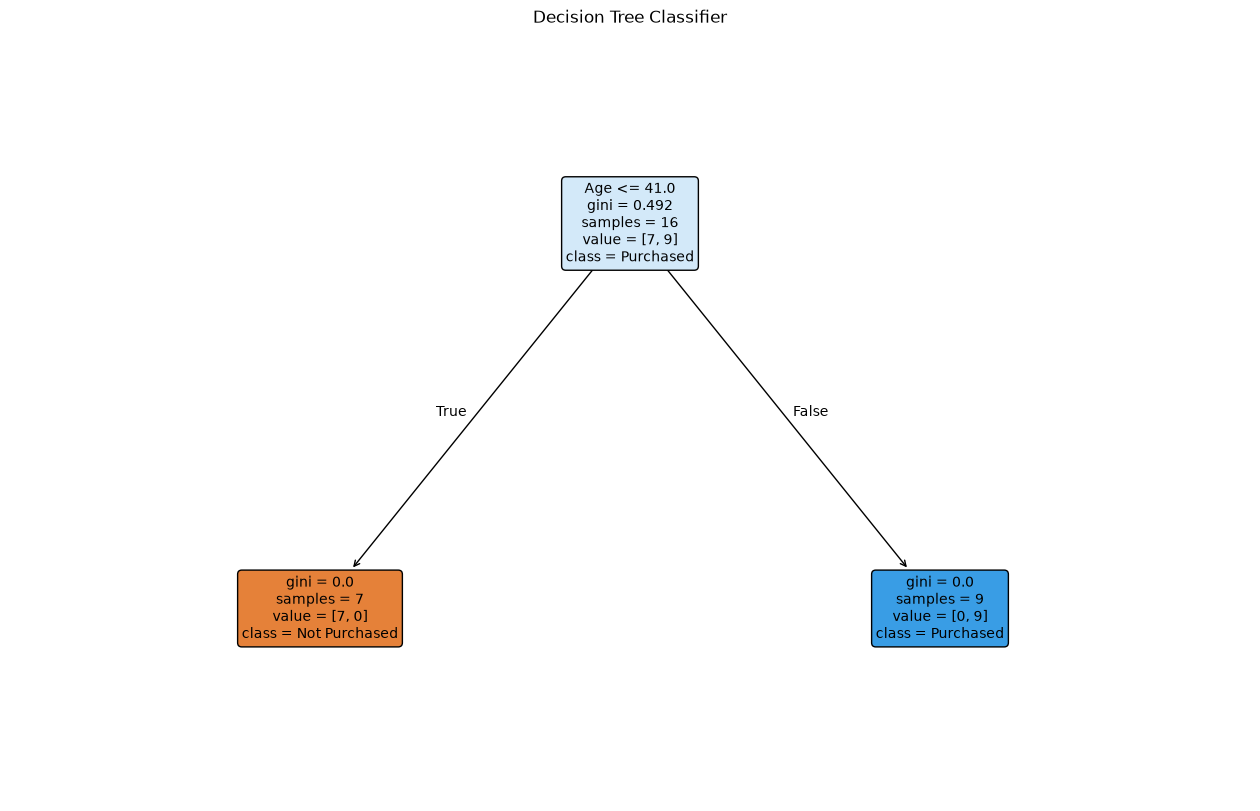

In [56]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create Dataset
data = {
    "Age": [22, 25, 47, 52, 46, 56, 23, 34, 45, 50,
            28, 40, 60, 35, 48, 30, 55, 27, 42, 58],

    "Salary": [20000, 25000, 50000, 60000, 45000, 80000,
               22000, 35000, 55000, 70000, 28000, 40000,
               90000, 32000, 52000, 30000, 85000, 26000,
               48000, 95000],

    "Purchased": [0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
                  0, 0, 1, 0, 1, 0, 1, 0, 1, 1]
}

df = pd.DataFrame(data)

# 1. Separate X and y
X = df[["Age", "Salary"]]
y = df["Purchased"]

# 2. Split Dataset (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Create Decision Tree Classifier
model = DecisionTreeClassifier(random_state=42)

# 4. Train Model
model.fit(X_train, y_train)

# 5. Predict Test Results
y_pred = model.predict(X_test)

print("Actual Results:")
print(list(y_test))

print("\nPredicted Results:")
print(y_pred)

# 6. Model Evaluation

# Accuracy Score
accuracy = accuracy_score(y_test, y_pred)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Classification Report
report = classification_report(y_test, y_pred)

print("\nAccuracy Score:", accuracy)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)

# 7. Predict for New Customer
new_customer = pd.DataFrame({
    "Age": [32],
    "Salary": [40000]
})

prediction = model.predict(new_customer)

if prediction[0] == 1:
    print("\nCustomer will PURCHASE")
else:
    print("\nCustomer will NOT PURCHASE")

# 8. Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

print("\nFeature Importance:")
print(importance.sort_values(
    by="Importance",
    ascending=False
))

# 9. Visualize Decision Tree
plt.figure(figsize=(16, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Not Purchased", "Purchased"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier")
plt.show()


In [2]:
import pandas as pd

df = pd.DataFrame({
    'city': ['Jaipur', 'Delhi', 'Jaipur', 'Delhi', 'Mumbai'],
    'sales': [100, 200, 300, 400, 500]
})

result = df.groupby('city')['sales'].mean()

print(result)

city
Delhi     300.0
Jaipur    200.0
Mumbai    500.0
Name: sales, dtype: float64


In [3]:
result = df.groupby('city')['sales'].transform('mean')

print(result)

0    200.0
1    300.0
2    200.0
3    300.0
4    500.0
Name: sales, dtype: float64


In [4]:
from torchvision import models

model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

print(model)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/ctpc-29/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|█████████████████████████████████████| 97.8M/97.8M [00:08<00:00, 11.7MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [5]:
import torch
from torchvision import models

weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

model.eval()

# Create a dummy image
dummy_image = torch.randn(1, 3, 224, 224)

# Make prediction
with torch.no_grad():
    output = model(dummy_image)

print("Output Shape:", output.shape)

Output Shape: torch.Size([1, 1000])


In [2]:
%pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.2/79.2 MB 11.3 MB/s  0:00:07 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 MB 11.4 MB/s  0:00:04 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics] 6/7 [ultralytics]lytics-platform]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO("yolo11n.pt")

# Detect objects in an image
results = model("car.jpg")

# Display detection results
for result in results:
    result.show()

FileNotFoundError: car.jpg does not exist